# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

Устройство: Google Colab, GPU Tesla T4

Ветка раздела 5: targeted (5.2)

Бонусы: 7.1-7.5

Источники: документация PyTorch, статьи из условия (He et al. 2015, Luo et al. 2016, Madry et al. 2017, Cohen et al. 2021, Wong et al. 2020)

Нерешенные задачи: нет, обязательная часть сделана полностью

Замечание к 6.3: input_gradient считает градиент по одной картинке, а не батчем. На GPU (Tesla T4) backward у MaxPool по-разному разрешает ничьи на фоне, где все пиксели равны нулю, для батча 1000 и батча 1. Из-за этого открытый тест 6.3 падал с расхождением 0.3. На CPU батчевая версия совпадает с ручным расчетом до 2e-7, то есть сама формула верная, и расхождение дает только реализация на GPU

In [7]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [8]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [9]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.5', '7.4'}      # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [10]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [11]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [12]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    cols = F.unfold(x, kernel_size=(kh, kw), dilation=dilation, padding=padding, stride=stride)

    cols = cols.view(B, groups, C_in // groups * kh * kw, H_out * W_out)
    w = weight.view(groups, C_out // groups, C_in // groups * kh * kw)

    out = torch.einsum('gop,bgpl->bgol', w, cols).reshape(B, C_out, H_out, W_out)

    if bias is not None:
        out = out + bias[None, :, None, None]
    return out

In [13]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [14]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.**

Получилось ровно $k^2$. При $stride=1$ и $padding=k//2$ число позиций $L=HW$ совпадает с числом пикселей, а каждый столбец хранит патч длины $Ck^2$, т е каждый пиксель входа копируется $k^2$ раз

Память и число умножений im2col растут как $k^2$. FFT-свертка поэлементно умножает спектры, дополненные до размера входа, и ее стоимость $O(HW\log HW)$ не зависит от $k$. Т е на больших ядрах квадратичный рост im2col делает FFT выгоднее

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [15]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding

        B, C_in, H, W = x.shape
        C_out, _, kh, kw = weight.shape
        H_out, W_out = grad_out.shape[-2:]

        op_h = H - ((H_out - 1) * s - 2 * p + kh)
        op_w = W - ((W_out - 1) * s - 2 * p + kw)

        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))

        cols = F.unfold(x, (kh, kw), padding=p, stride=s)
        grad_w = torch.einsum('bol,bpl->op', grad_out.reshape(B, C_out, -1), cols).reshape(weight.shape)
        grad_b = grad_out.sum(dim=(0, 2, 3))

        return grad_x, grad_w, grad_b, None, None

In [16]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.**

Для $3\times3$, stride 2, padding 1 входы $H=7$ и $H=8$ оба дают $H_\text{out}=4$. Transposed conv по умолчанию восстанавливает $(4-1)\cdot2-2+3=7$, поэтому для $H=7$ $outputpadding=0$, для $H=8-1$. Последняя строка при $H=8$ не попадает ни в один патч, и ее градиент нулевой


## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [17]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [18]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    y = model(x)

    center = y[:, :, y.shape[2] // 2, y.shape[3] // 2].sum()
    grad, = torch.autograd.grad(center, x)

    mask = grad[0].abs().sum(0) != 0
    rows = mask.any(dim=1).nonzero()
    cols = mask.any(dim=0).nonzero()

    return (rows.max() - rows.min() + 1).item(), (cols.max() - cols.min() + 1).item()

In [19]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.**

Веса положительные и нелинейностей нет, поэтому градиент не зависит от входа и строго положителен во всем теоретическом RF: обнулиться ему негде, ReLU не отрезает, разные знаки не сокращаются. Носитель совпадает с теоретическим RF, и проверка детерминирована

С MaxPool градиент в каждом окне идет только через argmax, остальные пиксели окна получают ноль, поэтому носитель становится разреженным и зависит от входа. При этом bbox в прогоне не изменился (conv-pool: 18×18, как и теоретический). Bbox определяется крайними точками, а на краю RF много окон, и достаточно, чтобы в одном из них максимум попал на внешний пиксель. Остальные три архитектуры pooling не содержат, для них флаг ничего не меняет. Разреженность носителя bbox не отражает. Чтобы ее увидеть, нужно считать долю ненулевых пикселей внутри bbox

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [20]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    x = torch.randn(n_inputs, in_channels, size, size, requires_grad=True)
    y = model(x)

    center = y[:, :, y.shape[2] // 2, y.shape[3] // 2].sum()
    grad, = torch.autograd.grad(center, x)

    g = grad.abs().mean(dim=0).sum(dim=0)
    p = g.sum(dim=1)
    p = p / p.sum()

    pos = torch.arange(size, dtype=p.dtype)
    mean = (p * pos).sum()

    return (p * (pos - mean) ** 2).sum().sqrt().item()

In [21]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [22]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


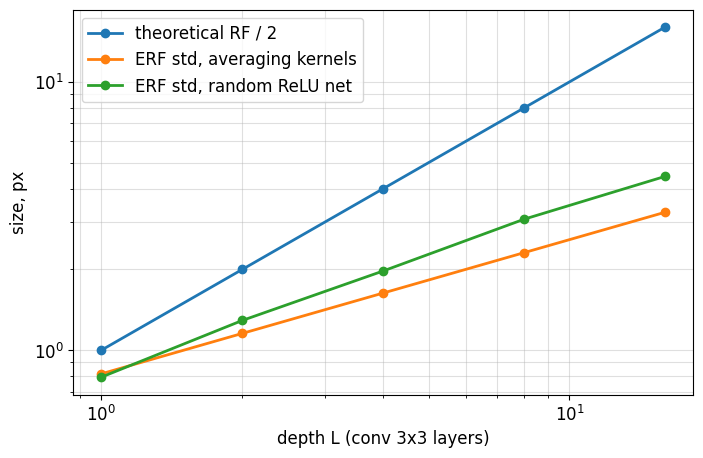

In [23]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.**

Теоретический RF растет линейно по глубине, ERF усредняющей сети - как $\sqrt L$. Поэтому отношение ERF/RF падает как $1/\sqrt L$: при $L=16$ ERF занимает около 20% от RF/2. Вклад пикселей сосредоточен в центре, профиль гауссовский по ЦПТ, и глубокая сеть фактически использует малую часть своего RF. ReLU-сеть со случайными весами растет быстрее, но все равно сублинейно

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [24]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), correction=0)
            n = x.numel() // x.shape[1]
            with torch.no_grad():
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mean)
                self.running_var.mul_(1 - self.momentum).add_(self.momentum * var * n / (n - 1))
                self.num_batches_tracked += 1
        else:
            mean, var = self.running_mean, self.running_var

        x_hat = (x - mean[None, :, None, None]) / torch.sqrt(var[None, :, None, None] + self.eps)
        return self.weight[None, :, None, None] * x_hat + self.bias[None, :, None, None]

In [25]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.**

В нормировку идет смещенная дисперсия, т к нормируется конкретный батч: деление на $n$ дает ровно его дисперсию, и после нормировки она равна 1. Running-дисперсия оценивает дисперсию всего распределения данных по выборке, поэтому применяется поправка $\frac{n}{n-1}$. При $B=4$ и карте $5\times5$ $n=100$, и оценки отличаются в $100/99 \approx 1.01$ раза. При $B=2$ и карте $1\times1$ $n=2$, и несмещенная вдвое больше смещенной. Кроме того, при $n=2$ нормированные значения всегда равны $\pm1$, и BN уничтожает информацию о входе

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.**

Свертка для выходного канала $o$: $z_o = W_o * x + b_o$ (если bias нет, $b_o = 0$). BN в eval():
$$y_o = \gamma_o \frac{z_o - \hat\mu_o}{\sqrt{\hat\sigma^2_o + \varepsilon}} + \beta_o$$
$$s_o = \dfrac{\gamma_o}{\sqrt{\hat\sigma^2_o + \varepsilon}}$$
$$y_o = s_o\,(W_o * x + b_o - \hat\mu_o) + \beta_o = (s_o W_o) * x + s_o(b_o - \hat\mu_o) + \beta_o$$
$$W'_o = s_o W_o, \qquad b'_o = s_o\,(b_o - \hat\mu_o) + \beta_o,$$

In [26]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size,
                      stride=conv.stride, padding=conv.padding, dilation=conv.dilation,
                      groups=conv.groups, bias=True, padding_mode=conv.padding_mode,
                      device=conv.weight.device, dtype=conv.weight.dtype)

    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    conv_bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)

    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    fused.bias.copy_((conv_bias - bn.running_mean) * scale + bn.bias)

    return fused


def fuse_sequential(seq):
    modules = list(seq)
    fused = []
    i = 0

    while i < len(modules):
        if (isinstance(modules[i], nn.Conv2d) and i + 1 < len(modules)
                and isinstance(modules[i + 1], nn.BatchNorm2d)):
            fused.append(fuse_conv_bn(modules[i], modules[i + 1]))
            i += 2
        else:
            fused.append(copy.deepcopy(modules[i]))
            i += 1

    return nn.Sequential(*fused)

In [27]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [28]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [29]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 125.7 ms   fused: 123.3 ms   speedup 1.02x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В `train()` BN нормирует по статистикам текущего батча, они меняются от батча к батчу, поэтому фиксированных $W', b'$ не существует. Кроме того, в обучении нужны градиенты через батч-статистики и обновление running-буферов. В `eval()` статистики заморожены, и BN становится фиксированным поканальным аффинным преобразованием, которое вливается в свертку без изменения результата.

Слияние убирает отдельный проход BN (чтение и запись всего тензора активаций плюс запуск ядра), FLOPs свертки не меняются. В нашем прогоне 125.7 мс -> 123.3 мс, ускорение всего 1.02x, что сравнимо с шумом замера. Причина в том, что свертки на 64 канала 3x3 (576 умножений на выходной элемент) доминируют по времени, а BN это дешевая поэлементная операция. Выигрыш больше там, где BN относительно дорог: узкие или depthwise свертки, маленькие тензоры, GPU, где BN упирается в пропускную способность памяти и запуск ядер. Если backend уже сам сливает операции (`torch.compile`, TensorRT), выигрыш близок к нулю.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.**

$\mathrm{Var}(h_i) = n v\, \mathbb E[z^2]$

Для ReLU при симметричном $h^{\text{prev}}$ обнуляется ровно половина значений: $\mathbb E[\mathrm{ReLU}(h)^2] = \tfrac12 \mathrm{Var}(h^{\text{prev}})$, откуда $\mathrm{Var}(h) = \tfrac{nv}{2}\mathrm{Var}(h^{\text{prev}})$ и $v = 2/n$

Для $\tanh$ в линейном режиме $\tanh(h) \approx h$, $\mathbb E[z^2] = \mathrm{Var}(h^{\text{prev}})$, откуда $v = 1/n$ (LeCun / Xavier для квадратного слоя). Дефолт PyTorch $\mathcal U(-1/\sqrt n, 1/\sqrt n)$ дает $v = \tfrac{1}{3n}$

для ReLU $\mathrm{Var}(h) = \tfrac16 \mathrm{Var}(h^{\text{prev}})$, т е std за слой уменьшается в $\sqrt 6 \approx 2.45$ раза

In [30]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)

    h = torch.randn(n, width)
    stds = []
    with torch.no_grad():
        for _ in range(depth):
            layer = nn.Linear(width, width, bias=False)
            init(layer.weight)
            h = act(layer(h))
            stds.append(h.std().item())
    return stds

In [31]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.4100027508284732)

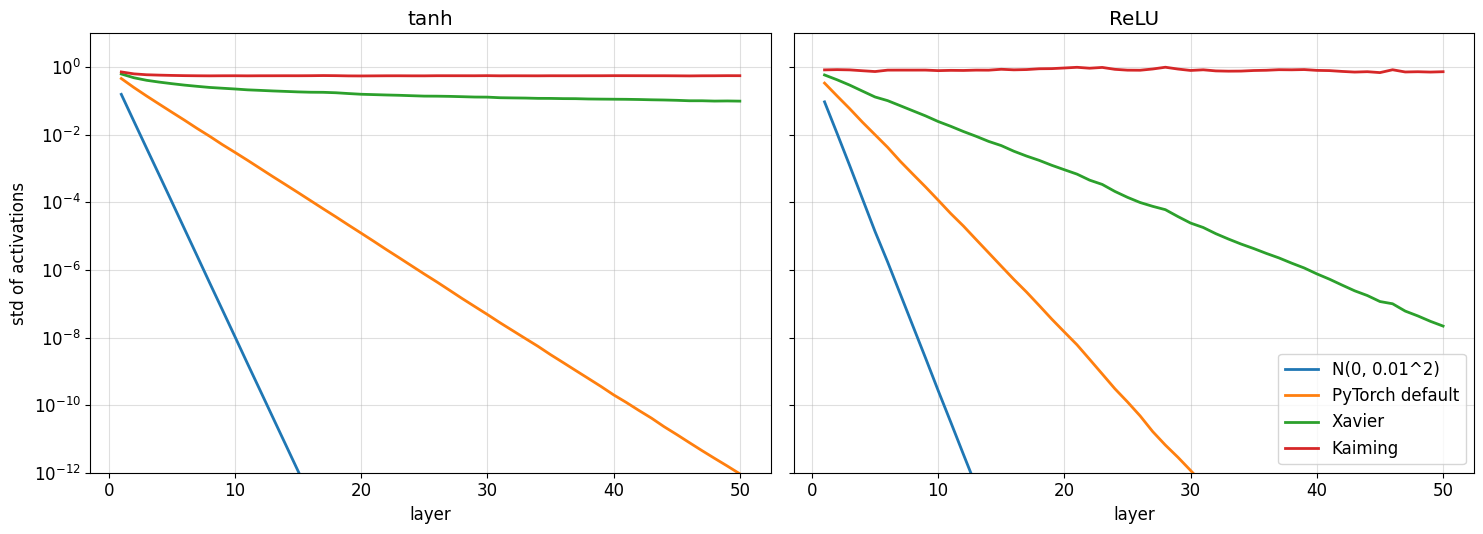

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.**

Масштаб на 50 слоях сохраняют Kaiming + ReLU (std держится = 0.8, last/first = 0.88) и Kaiming + tanh (= 0.6: по теории дисперсия растет в 2 раза за слой, но tanh насыщается и рост останавливается). Xavier + tanh почти сохраняет масштаб: std медленно падает с 0.6 до 0.1, потому что tanh вне нуля сжимает сигнал и линейное приближение выполняется лишь примерно

Остальные пары затухают экспоненциально, и наклоны совпадают с теорией: у Xavier + ReLU множитель $1/\sqrt2$ за слой, к 50-му слою $\approx 2\cdot10^{-8}$ (теория $2^{-25}\approx 3\cdot10^{-8}$). default + tanh - $1/\sqrt3$, к 50-му слою $\approx10^{-12}$ (теория $3^{-25}$). default + ReLU - $1/\sqrt6$ (измеренный rate = 0.41), $10^{-12}$ уже к +-30-му слою. $\mathcal N(0, 0.01^2)$ гасит сигнал за +-15 слоев

Сети с дефолтной инициализацией все равно обучаются: в ResNet после каждой свертки стоит BatchNorm, который возвращает активациям единичный масштаб независимо от масштаба весов, а residual-связи дают тождественный путь для сигнала и градиента. Еще глубина ResNet-20 меньше, а Adam нормирует шаг на величину градиента. Эксперимент - голый MLP без нормализации и skip-связей, и для него инициализация критична

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [33]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue

                state = self.state[p]
                if not state:
                    state['step'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)

                state['step'] += 1
                t = state['step']

                lr, eps = group['lr'], group['eps']
                p.mul_(1 - lr * group['weight_decay'])

                state['m'].mul_(beta1).add_(p.grad, alpha = 1 - beta1)
                state['v'].mul_(beta2).addcmul_(p.grad, p.grad, value = 1 - beta2)
                m_hat, v_hat = state['m'], state['v']

                if group['bias_correction']:
                    m_hat = m_hat / (1 - beta1 ** t)
                    v_hat = v_hat / (1 - beta2 ** t)

                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)

In [34]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [35]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


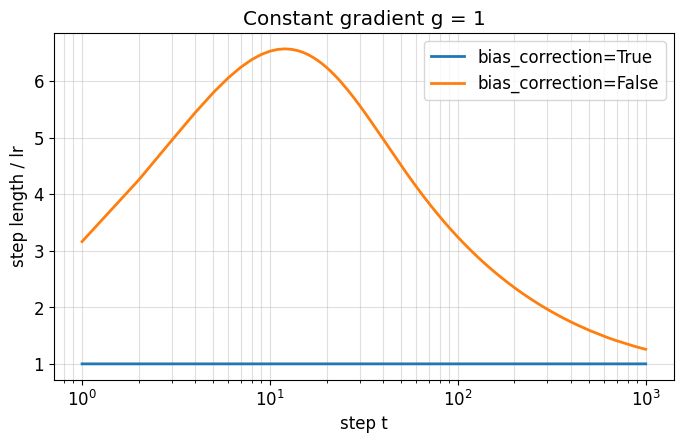

In [36]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.**

Без bias correction при $g_t \equiv 1$: $m_t = 1-\beta_1^t$, $v_t = 1-\beta_2^t$, длина шага $\Delta_t = \eta\,\frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}+\epsilon}$

При малых $t$ это $\approx \eta\,\frac{t(1-\beta_1)}{\sqrt{t(1-\beta_2)}} = \eta\sqrt t\,\frac{0.1}{\sqrt{0.001}}$: при $t=1$ шаг $\approx 3.16\eta$, максимум $\approx 6.6\eta$ около $t \approx 12$, при $t=100$ $\approx 3.2\eta$, при $t=1000$ $\approx 1.26\eta$ - совпадает с выводом ячейки

С поправкой шаг все время равен $\eta$ т к $v$ с $\beta_2 = 0.999$ «прогревается» за +-1000 шагов, а $m$ - за +-10, и знаменатель занижен сильнее числителя т е в начале обучения, когда веса случайные и градиенты большие, реальный шаг в несколько раз больше заданного lr, что может развалить обучение или выбросить веса в плохую область

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [37]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [38]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

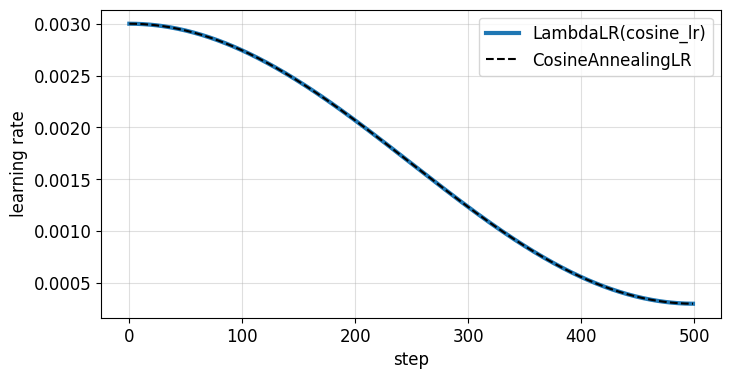

In [39]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.**

Адаптивность Adam - это нормировка шага на масштаб градиента ($\sqrt{v}$), но не подавление шума. Около минимума истинный градиент почти ноль, а стохастический градиент по мини-батчу состоит в основном из шума т е его нормированная величина остается порядка 1, поэтому шаг остается порядка lr. При постоянном шаге SGD/Adam не сходится к точке, а блуждает вокруг минимума в области, размер которой пропорционален lr. Уменьшение lr к концу обучения сужает эту область и позволяет осесть в минимуме: train loss заметно падает на последних эпохах. Большой lr в начале при этом нужен для быстрого движения и выхода из плохих областей

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [40]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [1:01:14<00:00, 46.4kB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

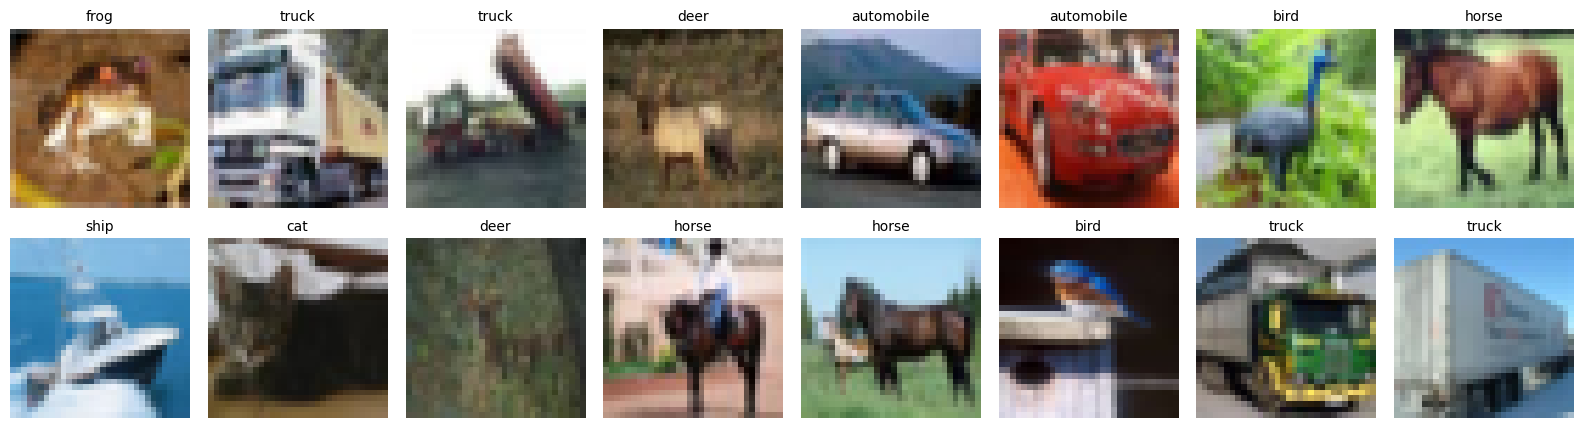

In [41]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [42]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False),
        )
    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)

        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(
                    nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                    nn.BatchNorm2d(c_out),
                )
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(),
        )

        blocks = []
        c_in = widths[0]
        for stage, width in enumerate(widths):
            for i in range(n):
                stride = 2 if stage > 0 and i == 0 else 1
                blocks.append(Block(c_in, width, stride, residual, separable))
                c_in = width

        self.stages = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(self.pool(x).flatten(1))

In [43]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [44]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    optimizer = MyAdamW([dict(params=decay, weight_decay=weight_decay),
                         dict(params=no_decay, weight_decay=0.0)], lr=lr)

    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps))

    for epoch in range(epochs):
        model.train()
        loss_sum = torch.zeros((), device=device)

        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * len(y)

        history['train_loss'].append(loss_sum.item() / len(X_train))
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))

        if log:
            print(f'epoch {epoch + 1}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  {time.time() - start:.0f}s')

    return history

In [45]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch 1/20  train loss 1.4331  test acc 0.5867  18s
epoch 2/20  train loss 0.9467  test acc 0.6201  33s
epoch 3/20  train loss 0.7635  test acc 0.6924  48s
epoch 4/20  train loss 0.6501  test acc 0.7103  63s
epoch 5/20  train loss 0.5671  test acc 0.7539  79s
epoch 6/20  train loss 0.4949  test acc 0.7231  94s
epoch 7/20  train loss 0.4331  test acc 0.7578  110s
epoch 8/20  train loss 0.3756  test acc 0.7865  127s
epoch 9/20  train loss 0.3172  test acc 0.7947  143s
epoch 10/20  train loss 0.2684  test acc 0.7950  159s
epoch 11/20  train loss 0.2134  test acc 0.8092  176s
epoch 12/20  train loss 0.1637  test acc 0.7999  192s
epoch 13/20  train loss 0.1096  test acc 0.8100  209s
epoch 14/20  train loss 0.0690  test acc 0.8204  226s
epoch 15/20  train loss 0.0390  test acc 0.8268  243s
epoch 16/20  train loss 0.0240  test acc 0.8290  260s
epoch 17/20  train loss 0.0166  test acc 0.8286  277s
epoch 18/20  train loss 0.0133  test acc 0.8286  294s
epoch 19/20  train loss 0.0114  test acc 0.

{'train acc': 1.0, 'test acc': 0.8287999629974365}

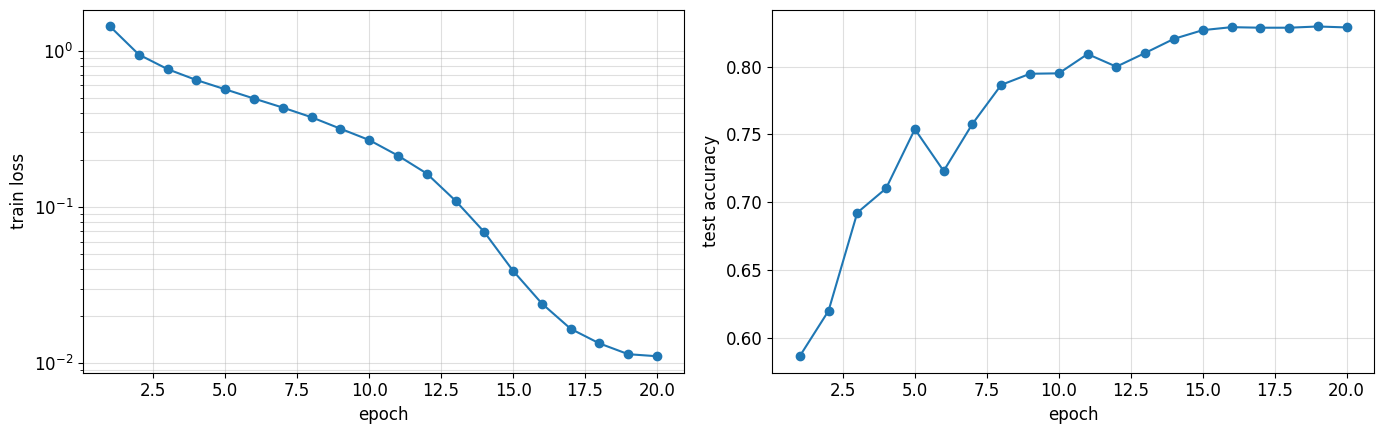

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В конце обучения train accuracy 1.000, test accuracy 0.829, разрыв около 17 процентных пунктов. Аугментаций нет, поэтому сеть полностью запоминает train, это обычное переобучение. На последних эпохах, когда learning rate уходит к нулю, train loss быстро падает: 0.27 на 10 эпохе, 0.039 на 15 и 0.011 на 20. Test accuracy при этом выходит на плато, с 16 по 20 эпоху она держится около 0.829 и почти не меняется. В середине обучения при большом lr test accuracy заметно скачет (0.754 на 5 эпохе и 0.723 на 6, 0.809 на 11 и 0.800 на 12), а к концу кривая сглаживается, потому что шаги становятся маленькими и модель оседает в минимуме. Ориентир 0.82 достигнут.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [47]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [48]:
ablation = {}
for name, cfg in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**cfg)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    ablation[name] = dict(
        params=n_params(model),
        train_acc=accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000]),
        test_acc=hist['test_acc'][-1],
        minutes=(time.perf_counter() - started) / 60,
        history=hist,
    )

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

epoch 1/10  train loss 1.7051  test acc 0.3908  16s
epoch 2/10  train loss 1.3278  test acc 0.5302  33s
epoch 3/10  train loss 1.0675  test acc 0.6137  49s
epoch 4/10  train loss 0.9067  test acc 0.6496  65s
epoch 5/10  train loss 0.7918  test acc 0.6849  81s
epoch 6/10  train loss 0.6905  test acc 0.7044  98s
epoch 7/10  train loss 0.6027  test acc 0.7561  114s
epoch 8/10  train loss 0.5332  test acc 0.7748  130s
epoch 9/10  train loss 0.4797  test acc 0.7870  147s
epoch 10/10  train loss 0.4528  test acc 0.7859  163s
epoch 1/10  train loss 1.9570  test acc 0.2511  49s
epoch 2/10  train loss 1.8127  test acc 0.2634  99s
epoch 3/10  train loss 1.6837  test acc 0.3352  148s
epoch 4/10  train loss 1.5498  test acc 0.3982  197s
epoch 5/10  train loss 1.4317  test acc 0.4545  247s
epoch 6/10  train loss 1.3202  test acc 0.4993  296s
epoch 7/10  train loss 1.2103  test acc 0.5323  345s
epoch 8/10  train loss 1.1225  test acc 0.5732  395s
epoch 9/10  train loss 1.0530  test acc 0.6028  444s


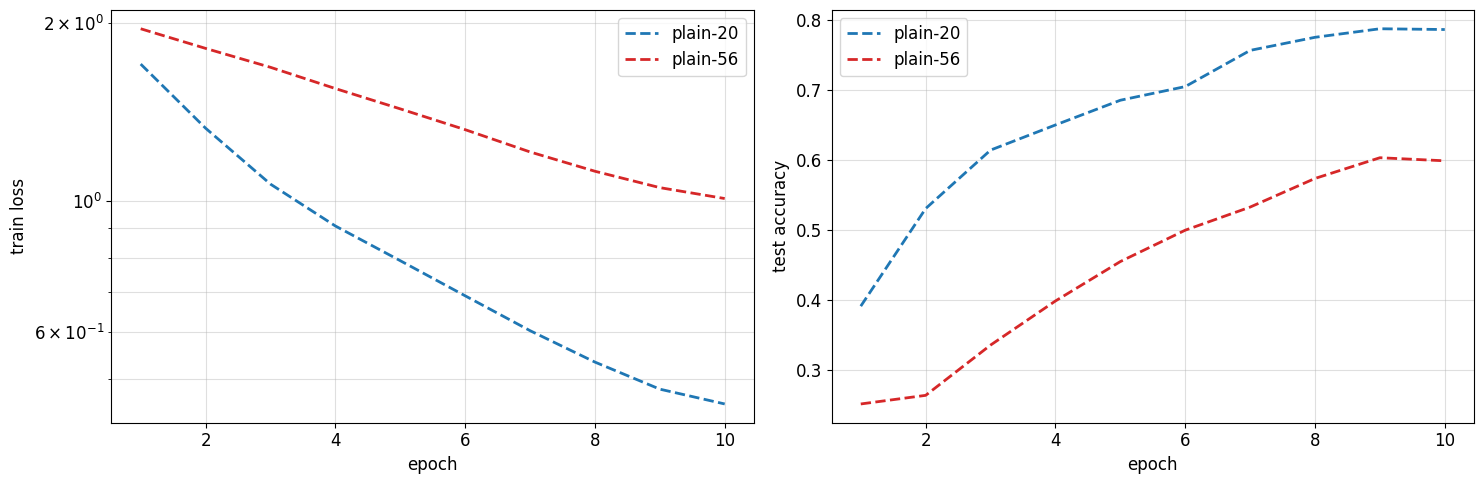

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Да, ухудшение на train есть. За 10 эпох plain-20 дошла до train loss 0.45 и train accuracy 0.855, а plain-56 только до train loss 1.01 и train accuracy 0.635. Test accuracy тоже ниже, 0.786 против 0.598. При этом разрыв между train и test у обеих сетей небольшой (0.07 у plain-20 и 0.04 у plain-56), а параметров у plain-56 в три раза больше (853 тыс против 270 тыс). Значит, это не переобучение. Переобучение выглядело бы наоборот: на train лучше, на test хуже. Здесь более глубокая сеть хуже даже на train, то есть ей труднее оптимизироваться, это degradation problem из статьи He et al. Есть ограничение: loss у plain-56 к 10 эпохе еще падает, поэтому по одному короткому прогону нельзя точно отличить ситуацию "не может обучиться" от "обучается медленнее". Контрольный эксперимент: обучить ResNet-56 с residual-связями по тому же протоколу (10 эпох, тот же lr и seed). Если она по train loss окажется не хуже plain-20, значит, проблема именно в оптимизации глубокой plain-сети, а не в числе параметров или бюджете эпох.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [50]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.75MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [51]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [52]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [53]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.918, 'FGSM, eps=0.1': 0.072, 'PGD-20, eps=0.1': 0.006}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [54]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()

    for i in range(steps):
        x_adv.requires_grad_(True)

        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)

        grad_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        x_adv = x_adv.detach() + alpha * grad / grad_norm

        delta = x_adv - x
        delta_norm = delta.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        delta = delta * torch.clamp(eps / delta_norm, max=1.0)

        x_adv = (x + delta).clamp(0, 1)

    return x_adv.detach()

In [55]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.922; маленькое падение требует диагностики.


(0.922, 0.0)

In [56]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.918,
  0.5: 0.442,
  1.0: 0.077,
  1.5: 0.011,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.006)

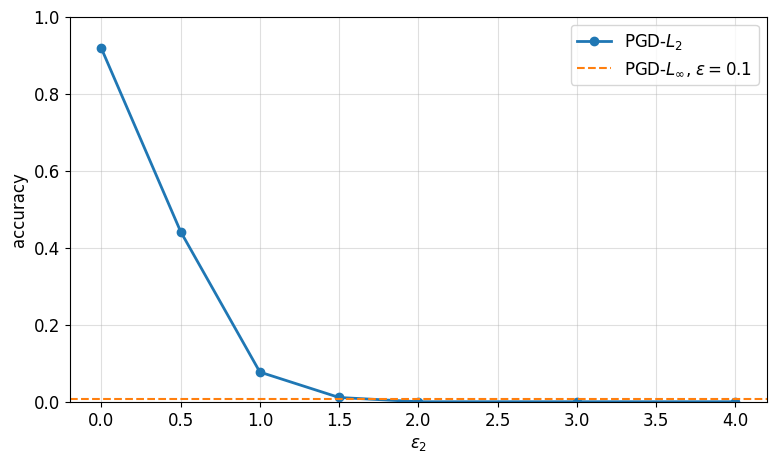

In [57]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.005


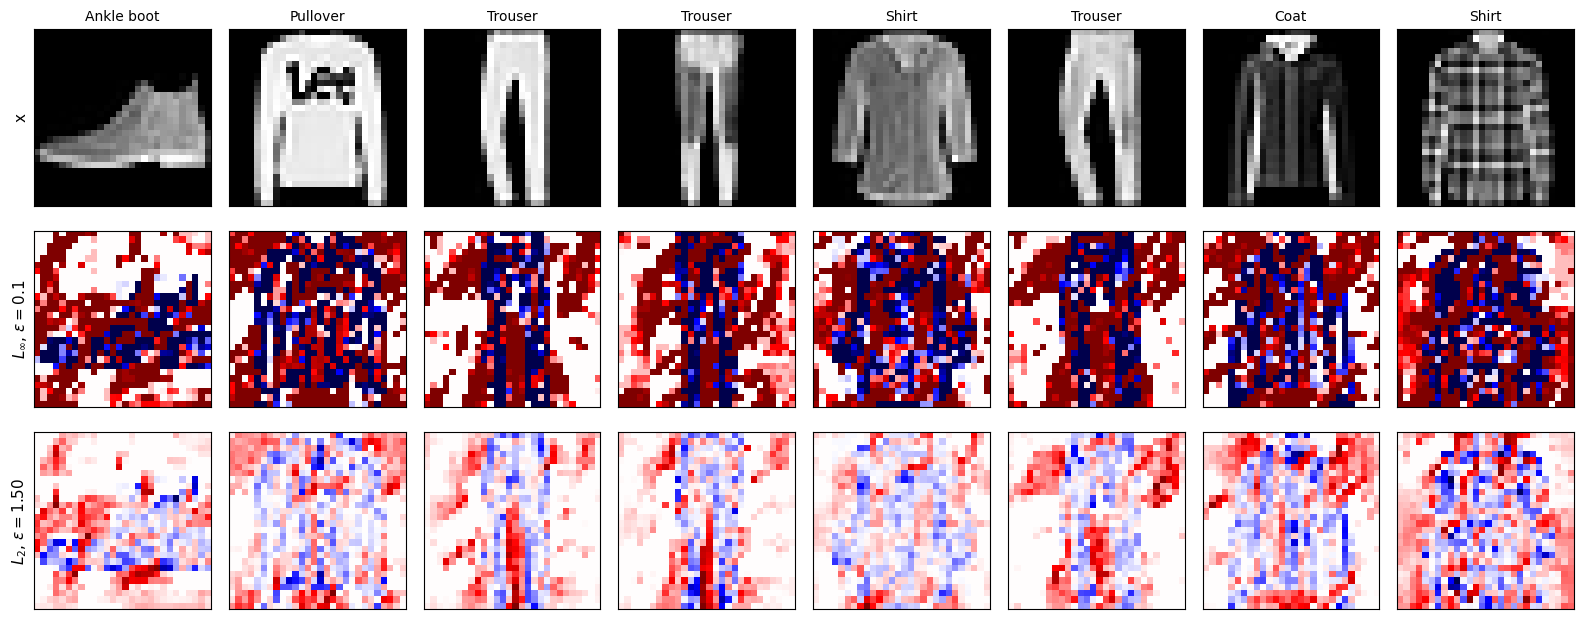

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.103
$L_2$, $\varepsilon=1.50$    L_inf = 0.258   L_2 = 1.492


In [58]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближе всего по accuracy к $L_\infty$-атаке с eps = 0.1 (accuracy 0.006) точка eps2 = 1.5 (accuracy 0.011), остаточный разрыв всего 0.005, так что атаки можно считать примерно равными по силе. L2-норма самого $L_\infty$-возмущения в среднем 2.10 при $L_\infty$-норме ровно 0.1. Максимум 0.1 * 28 = 2.8 не достигается, потому что на черном фоне пиксели равны нулю и уменьшать их некуда, отрицательные шаги обрезаются клипом в [0, 1]. Поэтому на картах фон у $L_\infty$-атаки в основном красный. L2-атака при той же силе тратит меньший бюджет (L2 = 1.49), зато отдельные пиксели меняются до 0.26. $L_\infty$-возмущение размазано почти по всей картинке с одинаковой амплитудой, потому что шаг по знаку градиента сдвигает каждый пиксель на одну и ту же величину. L2-возмущение сосредоточено на силуэте предмета, его краях и деталях, а большая часть фона почти не тронута. Это следствие шага по нормированному градиенту: бюджет распределяется пропорционально величине градиента, и сильнее всего меняются пиксели, к которым модель наиболее чувствительна.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [59]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)

        for i in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)

            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        hits = torch.zeros(n_classes, n_classes)

        for t in range(n_classes):
            mask = y != t
            xs, ys = x[mask], y[mask]

            for i in range(0, len(xs), 128):
                xb, yb = xs[i:i + 128], ys[i:i + 128]
                x_adv = pgd_targeted(model, xb, torch.full_like(yb, t), eps, alpha=2.5 * eps / steps, steps=steps)

                with torch.no_grad():
                    hit = model(x_adv).argmax(dim=1) == t

                hits[:, t] += torch.bincount(yb[hit], minlength=n_classes).cpu().float()

        counts = torch.bincount(y, minlength=n_classes).cpu().float()
        S = hits / counts[:, None]
        S[counts == 0] = float('nan')
        S.fill_diagonal_(float('nan'))

        return S

In [60]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.766; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.89 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.06 0.   0.75 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


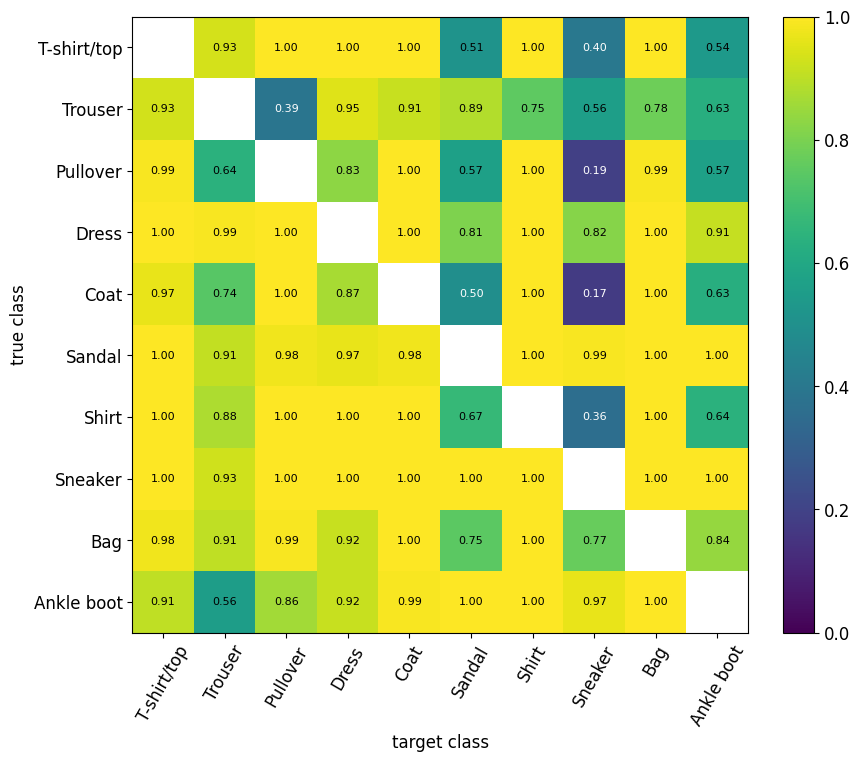

In [61]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Легче всего атакуются пары внутри визуально похожих групп. Внутри верхней одежды (T-shirt, Pullover, Coat, Shirt) успех почти везде 0.97-1.00, внутри обуви тоже около 1 (Sandal в Sneaker 0.99, Ankle boot в Sneaker 0.97). Цели Shirt и Bag достигаются почти из любого класса, а Sneaker атакуется в любой класс с успехом 0.93-1.00. Труднее всего пары между разными группами, особенно когда цель это обувь, а исходник большая светлая вещь: Coat в Sneaker 0.17, Pullover в Sneaker 0.19, Shirt в Sneaker 0.36, T-shirt в Sneaker 0.40, Coat в Sandal 0.50. Чтобы превратить пальто в кроссовок, нужно погасить большую яркую область, а при eps = 0.1 каждый пиксель можно изменить только на 0.1. Матрица сильно несимметрична: Sneaker в Pullover и Sneaker в Coat 1.00, а обратно 0.19 и 0.17, Trouser в Pullover 0.39, а Pullover в Trouser 0.64. Связь с clean confusion matrix есть. Без атаки модель путает как раз классы внутри групп (Shirt с T-shirt 0.09, Coat с Pullover 0.06, Pullover с Coat и Shirt по 0.05, Ankle boot со Sneaker 0.04), граница решений между ними близко, и атака туда проходит почти всегда. Но при eps = 0.1 успешны и многие пары, которые без атаки не путаются вовсе. Так что clean ошибки объясняют только самые легкие пары, а трудность остальных определяется тем, насколько сильно нужно изменить картинку.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [62]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [63]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [64]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    x_eval, y_eval = XF_test[:1000], YF_test[:1000]
    start = time.time()

    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps)
            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        history['clean'].append(attack_accuracy(model, x_eval, y_eval))
        history['fgsm'].append(attack_accuracy(model, x_eval, y_eval, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, x_eval, y_eval, pgd, eps=eps))

        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  '
                  f'FGSM {history["fgsm"][-1]:.3f}  PGD-20 {history["pgd"][-1]:.3f}  {time.time() - start:.0f}s')

    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [65]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5  clean 0.806  FGSM 0.697  PGD-20 0.664  9s
epoch 2/5  clean 0.822  FGSM 0.699  PGD-20 0.663  19s
epoch 3/5  clean 0.821  FGSM 0.723  PGD-20 0.694  28s
epoch 4/5  clean 0.833  FGSM 0.720  PGD-20 0.694  37s
epoch 5/5  clean 0.842  FGSM 0.746  PGD-20 0.723  46s


In [66]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.918   0.124   0.006   0.000   0.000   0.000
PGD-AT       0.842   0.784   0.722   0.474   0.129   0.002


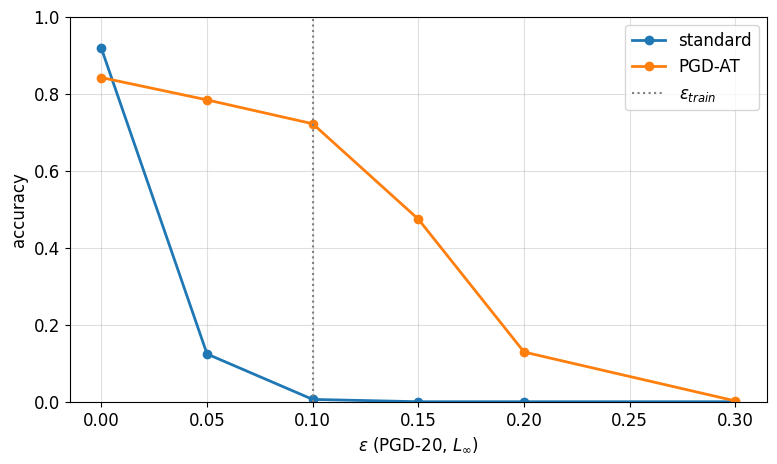

In [67]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Clean accuracy упала с 0.918 у обычной модели до 0.842 у PGD-AT, то есть робастность стоит примерно 7.6 процентного пункта. Взамен при eps = 0.1 PGD-20 accuracy выросла с 0.006 до 0.722, а при eps = 0.05 с 0.124 до 0.784. При eps больше eps_train устойчивость быстро пропадает: 0.474 при 0.15, 0.129 при 0.2 и 0.002 при 0.3. Модель училась защищаться только внутри шара радиуса 0.1, и за его пределами гарантий нет, хотя рядом с 0.15 запас еще остается. По числу проходов PGD-7 на каждый батч делает 7 forward/backward для атаки и еще один для шага оптимизатора, итого 8 вместо одного, то есть примерно в 8 раз дороже. По времени вышло 45.9 с против 7.5 с у обычного обучения при тех же 5 эпохах, примерно в 6 раз. Это меньше 8, потому что backward атаки считается только по входу, без градиентов весов и шага оптимизатора, и часть накладных расходов на батч не умножается (при этом в 45.9 с еще входит оценка после каждой эпохи).

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [68]:
def sanity_checks(model, x, y, eps):
    model.eval()

    def correct_on(x_in, y_in):
        with torch.no_grad():
            return model(x_in).argmax(dim=1) == y_in

    results = dict(fgsm=[], pgd20=[], pgd100_x5=[], eps_1=[])
    for i in range(0, len(x), 128):
        xb, yb = x[i:i + 128], y[i:i + 128]
        clean = correct_on(xb, yb)

        results['fgsm'].append(clean & correct_on(fgsm_attack(model, xb, yb, eps), yb))
        results['pgd20'].append(clean & correct_on(pgd(model, xb, yb, eps, steps=20), yb))

        survived = clean.clone()
        for j in range(5):
            survived &= correct_on(pgd(model, xb, yb, eps, steps=100), yb)

        results['pgd100_x5'].append(survived)
        results['eps_1'].append(clean & correct_on(pgd(model, xb, yb, 1.0, steps=20), yb))

    return {k: torch.cat(v).float().mean().item() for k, v in results.items()}

In [69]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.086      0.012      0.008      0.000
PGD-AT                      0.742      0.734      0.734      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** У PGD-AT accuracy не растет при усилении атаки: FGSM 0.742, PGD-20 0.734, PGD-100 с пятью рестартами тоже 0.734. Переход от одного шага к 20 снимает 0.8 пункта, а 100 шагов и 5 рестартов не ломают ни одного дополнительного объекта, то есть атака сошлась уже за 20 шагов и оценка стабильна. У обычной модели 0.086, 0.012 и 0.008. При eps = 1 обе модели дают 0, значит, градиенты рабочие и атака действительно может дойти до любой картинки. Явно подозрительных результатов нет. Маленький разрыв между FGSM и PGD у PGD-AT ожидаем для модели, обученной на PGD, но похожую картину могло бы дать и gradient masking. Оценка сделана на 256 объектах и только градиентными атаками, поэтому дополнительно я бы проверил атаку без градиентов (например Square Attack или AutoAttack), transfer-атаку с обычной модели и график loss по итерациям PGD. Модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройдет все эти проверки: сильная атака дает меньше, чем слабая, а при eps = 1 accuracy нулевая. При этом робастной она не является. Ее настоящая robust accuracy около нуля, а высокая FGSM accuracy значит лишь то, что одношаговая линеаризация на ней не работает, это типичный признак gradient masking или catastrophic overfitting (как у FGSM-AT в 7.5). Robustness нужно оценивать по самой сильной атаке, а прохождение sanity checks ее не доказывает.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [70]:
def input_gradient(model, x, y):
    model.eval()
    grads = []
    for i in range(len(x)):
        xi = x[i:i + 1].detach().clone().requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(model(xi)[0, y[i]], xi)
        grads.append(grad.abs())
    return torch.cat(grads)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [71]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5940874218940735, 'PGD-AT': 0.22389645874500275}

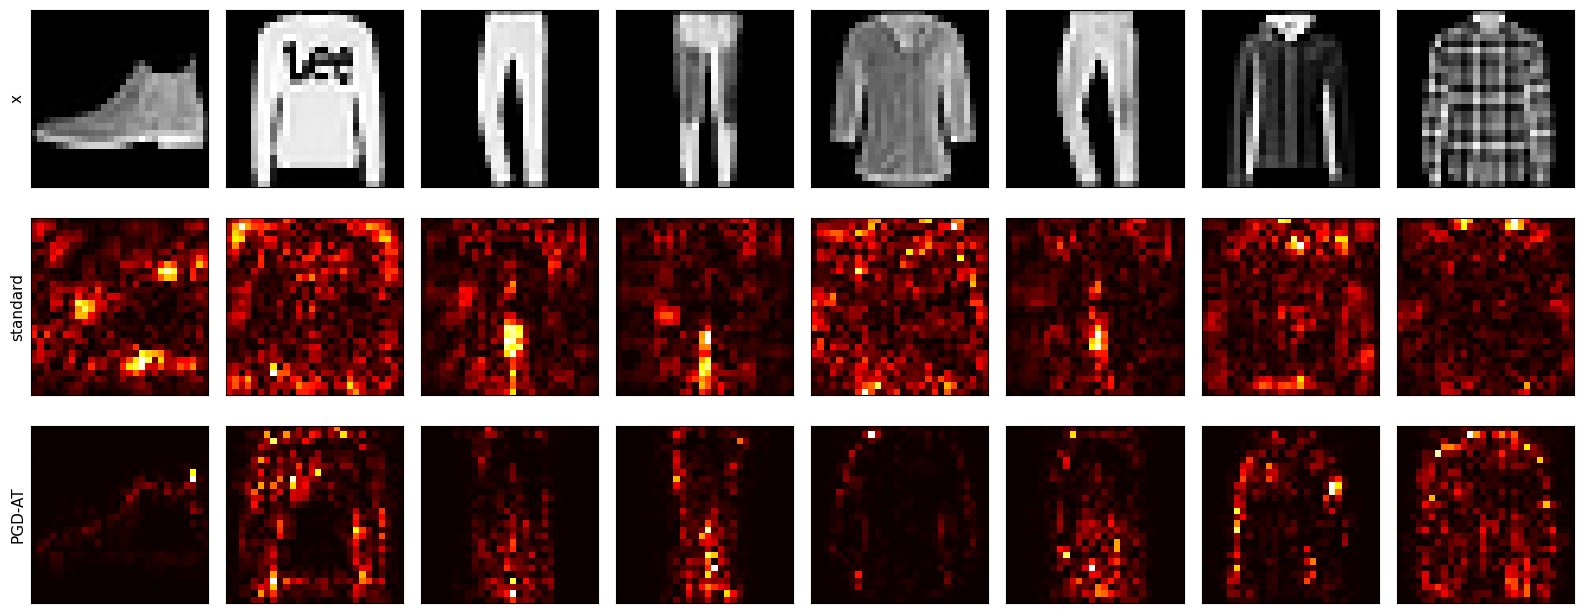

In [72]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** У обычной модели карта градиента шумная и размазана по всей картинке, включая фон, яркие точки встречаются в случайных местах вокруг предмета. Доля массы градиента на фоне 0.594, а сам фон занимает 0.498 пикселей, то есть на фон приходится даже больше его доли. У PGD-AT фон почти черный, градиент сосредоточен на силуэте и деталях предмета (хорошо видны контуры пуловера и пальто), доля на фоне 0.224. Это согласуется с разницей в PGD accuracy при eps = 0.1 (0.006 у обычной модели против 0.722 у PGD-AT): обычная модель чувствительна к изменениям фона, которые для человека ничего не значат, и именно их использует атака. Но одной красивой карты мало для вывода о robustness. Saliency показывает градиент в одной точке, то есть поведение модели в бесконечно малой окрестности, а атака ищет худшее возмущение в шаре конечного радиуса. Модель с gradient masking тоже может давать аккуратные карты и при этом оставаться уязвимой. К тому же визуальная оценка субъективна и сделана по 8 картинкам. Robustness проверяется только атаками.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [73]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [74]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        return torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [75]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [76]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

initial sharpness 4.44, lrs: 0.2253, 0.1126, 0.0563
      lr     2/lr  max sharp  last sharp  first loss  last loss
  0.2253     8.88      10.86        9.92      0.4973     0.0664
  0.1126    17.76      20.41       19.27      0.4973     0.0928
  0.0563    35.51      38.25       36.94      0.4973     0.1041


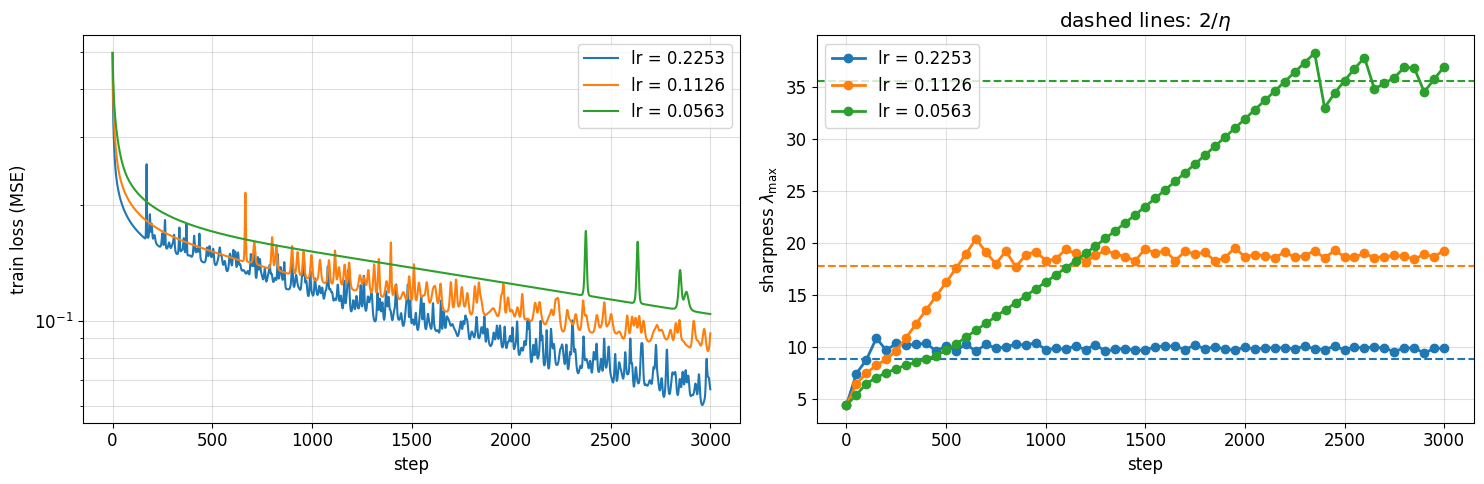

In [77]:
if '7.1' in BONUS_TASKS:
    probe = make_tanh_mlp(seed=0)
    lam0, _ = top_eigenvalue(lambda: mse_loss(probe), list(probe.parameters()), iters=20)
    EOS_LRS = [2 / (k * lam0) for k in (2, 4, 8)]
    print(f'initial sharpness {lam0:.2f}, lrs: ' + ', '.join(f'{lr:.4f}' for lr in EOS_LRS))

    eos = {}
    for lr in EOS_LRS:
        model = make_tanh_mlp(seed=0)
        params = list(model.parameters())
        optimizer = torch.optim.SGD(params, lr=lr)
        losses, sharp_steps, sharpness = [], [], []
        v = None

        for step in range(EOS_STEPS + 1):
            if step % 50 == 0:
                lam, v = top_eigenvalue(lambda: mse_loss(model), params, iters=20, v=v)
                sharp_steps.append(step)
                sharpness.append(lam)

            if step == EOS_STEPS:
                break

            loss = mse_loss(model)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        eos[lr] = dict(loss=losses, steps=sharp_steps, sharpness=sharpness)

    print(f'{"lr":>8}{"2/lr":>9}{"max sharp":>11}{"last sharp":>12}{"first loss":>12}{"last loss":>11}')
    for lr, res in eos.items():
        print(f'{lr:>8.4f}{2 / lr:>9.2f}{max(res["sharpness"]):>11.2f}{res["sharpness"][-1]:>12.2f}'
              f'{res["loss"][0]:>12.4f}{res["loss"][-1]:>11.4f}')

    colors = ['tab:blue', 'tab:orange', 'tab:green']
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    for (lr, res), color in zip(eos.items(), colors):
        ax1.semilogy(res['loss'], color=color, linewidth=1.5, label=f'lr = {lr:.4f}')
        ax2.plot(res['steps'], res['sharpness'], 'o-', color=color, linewidth=2, label=f'lr = {lr:.4f}')
        ax2.axhline(2 / lr, color=color, linestyle='--', linewidth=1.5)

    ax1.set_xlabel('step')
    ax1.set_ylabel('train loss (MSE)')
    ax2.set_xlabel('step')
    ax2.set_ylabel(r'sharpness $\lambda_{\max}$')
    ax2.set_title(r'dashed lines: $2/\eta$')

    for ax in (ax1, ax2):
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Начальная sharpness 4.44, learning rate выбраны так, чтобы 2/η была в 2, 4 и 8 раз выше нее: η = 0.2253, 0.1126 и 0.0563 (2/η = 8.88, 17.76 и 35.51). Во всех трех прогонах sharpness дошла до 2/η. Сначала она растет почти линейно (progressive sharpening). Граница достигнута примерно к 150 шагу при η = 0.2253, около 600 шага при η = 0.1126 и только около 2200 шага при η = 0.0563. Дальше рост останавливается и sharpness колеблется чуть выше границы: в конце 9.92, 19.27 и 36.94, примерно на 5-10% выше 2/η. Loss ведет себя согласованно. Пока sharpness ниже 2/η, loss падает гладко и монотонно, это хорошо видно на зеленой кривой до ~2200 шага. После выхода на границу появляются резкие всплески (у зеленой около 2400, 2650 и 2850 шагов, синяя и оранжевая шумят почти все время), но в среднем loss продолжает убывать: финальный loss 0.066, 0.093 и 0.104. Для фиксированной квадратичной функции гессиан постоянный, и при λmax > 2/η GD неизбежно расходится вдоль верхнего собственного направления. У нейросети гессиан зависит от параметров. Когда шаг начинает раскачиваться вдоль крутого направления, эта раскачка сама сдвигает параметры в область с меньшей кривизной, и sharpness возвращается к границе. Локальный квадратичный критерий описывает только одну точку и не учитывает, как кривизна меняется по траектории, поэтому такую самостабилизацию он не предсказывает

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [78]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        x = F.pad(x, (padding, padding, padding, padding))

        B, C_in, H, W = x.shape
        C_out, C_g, kh, kw = weight.shape

        fh, fw = H + kh - 1, W + kw - 1
        x_f = torch.fft.rfft2(x, s=(fh, fw)).view(B, groups, C_in // groups, fh, fw // 2 + 1)
        w_f = torch.fft.rfft2(weight.flip(-2, -1), s=(fh, fw)).view(groups, C_out // groups, C_g, fh, fw // 2 + 1)
        y_f = torch.einsum('bgchw,gochw->bgohw', x_f, w_f).reshape(B, C_out, fh, fw // 2 + 1)
        y = torch.fft.irfft2(y_f, s=(fh, fw))

        y = y[:, :, kh - 1:H, kw - 1:W][:, :, ::stride, ::stride]

        if bias is not None:
            y = y + bias[None, :, None, None]

        return y

In [79]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** FFT считает полную свертку размера (H+k-1)×(W+k-1), из нее нужна только valid-часть (H-k+1)×(W-k+1), а при stride s из valid-части остается каждый s-й выход по обеим осям, то есть доля 1/s². Значит, даже внутри valid-области выбрасывается 1 - 1/s² посчитанных выходов: 75% при s = 2 и около 89% при s = 3, плюс вся граница полной свертки. Прямая свертка со stride сразу считает только нужные выходы, поэтому stride бьет именно по FFT. FFT выгоднее при больших ядрах и stride 1. Стоимость прямой свертки растет как k² на каждый выход (как и размер cols в 1.1), а у FFT почти не зависит от k, это порядка HW log(HW) на канал плюс поэлементное умножение спектров. Еще помогают много каналов и большие картинки: спектр каждого входного канала и каждого фильтра считается один раз и потом переиспользуется. Для ядер 3×3, как в обычных CNN, прямой метод через im2col и GEMM обычно быстрее.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [80]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs
        X = M / M.norm().clamp_min(1e-7)

        transposed = X.shape[0] > X.shape[1]
        if transposed:
            X = X.T

        for _ in range(steps):
            A = X @ X.T
            X = a * X + (b * A + c * A @ A) @ X

        return X.T if transposed else X


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue

                    state = self.state[p]
                    if not state:
                        state['momentum_buffer'] = torch.zeros_like(p)

                    buf = state['momentum_buffer']
                    buf.mul_(mu).add_(p.grad, alpha=1 - mu)

                    update = (1 - mu) * p.grad + mu * buf
                    matrix = update.reshape(p.shape[0], -1)
                    rows, cols = matrix.shape
                    scale = math.sqrt(max(1, rows / cols))

                    p.add_(newton_schulz(matrix).reshape(p.shape), alpha=-group['lr'] * scale)

In [81]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [82]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02

    set_seed(0)
    model_muon = ResNetCIFAR(20).to(device)

    conv_params = [p for p in model_muon.parameters() if p.ndim == 4]
    other_params = [p for p in model_muon.parameters() if p.ndim != 4]

    optimizers = [
        ConvMuon(conv_params, lr=MUON_LR),
        MyAdamW([dict(params=[p for p in other_params if p.ndim > 1], weight_decay=0.05),
                 dict(params=[p for p in other_params if p.ndim <= 1], weight_decay=0.0)], lr=LR),
    ]

    total_steps = EPOCHS * math.ceil(len(X_train) / 256)
    schedulers = [torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, total_steps)) for opt in optimizers]
    hist_muon = dict(train_loss=[], test_acc=[])
    start = time.time()

    for epoch in range(EPOCHS):
        model_muon.train()
        loss_sum = torch.zeros((), device=device)

        for x, y in iterate_batches(X_train, Y_train, 256, transform=normalize):
            loss = F.cross_entropy(model_muon(x), y)

            for opt in optimizers:
                opt.zero_grad()
            loss.backward()

            for opt in optimizers:
                opt.step()
            for sch in schedulers:
                sch.step()

            loss_sum += loss.detach() * len(y)

        hist_muon['train_loss'].append(loss_sum.item() / len(X_train))
        hist_muon['test_acc'].append(accuracy(predict_logits(model_muon, X_test, transform=normalize), Y_test))

        print(f'epoch {epoch + 1}/{EPOCHS}  train loss {hist_muon["train_loss"][-1]:.4f}  '
              f'test acc {hist_muon["test_acc"][-1]:.4f}  {time.time() - start:.0f}s')

    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

epoch 1/20  train loss 1.1493  test acc 0.6433  18s
epoch 2/20  train loss 0.6616  test acc 0.7424  35s
epoch 3/20  train loss 0.5036  test acc 0.7668  53s
epoch 4/20  train loss 0.3949  test acc 0.8082  70s
epoch 5/20  train loss 0.3105  test acc 0.8030  88s
epoch 6/20  train loss 0.2434  test acc 0.8133  105s
epoch 7/20  train loss 0.1788  test acc 0.8346  123s
epoch 8/20  train loss 0.1288  test acc 0.8318  141s
epoch 9/20  train loss 0.0897  test acc 0.8289  158s
epoch 10/20  train loss 0.0615  test acc 0.8421  176s
epoch 11/20  train loss 0.0409  test acc 0.8343  193s
epoch 12/20  train loss 0.0279  test acc 0.8370  211s
epoch 13/20  train loss 0.0171  test acc 0.8453  228s
epoch 14/20  train loss 0.0103  test acc 0.8512  246s
epoch 15/20  train loss 0.0059  test acc 0.8490  263s
epoch 16/20  train loss 0.0031  test acc 0.8516  281s
epoch 17/20  train loss 0.0017  test acc 0.8509  298s
epoch 18/20  train loss 0.0011  test acc 0.8517  316s
epoch 19/20  train loss 0.0008  test acc 0

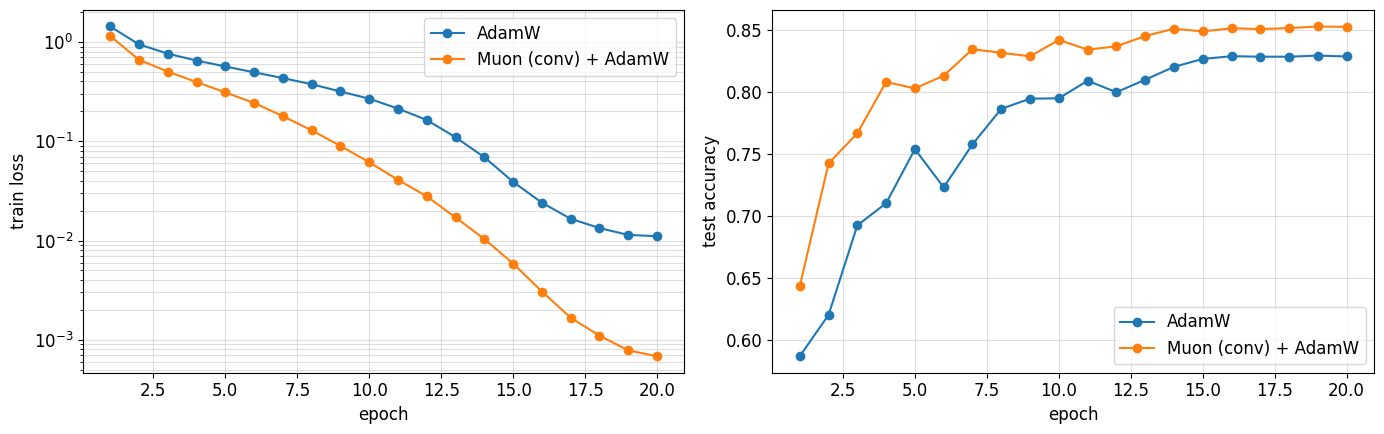

In [83]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Muon для сверточных весов заметно быстрее снижает train loss: к 10 эпохе 0.062 против примерно 0.26 у AdamW, в конце 0.0007 против 0.011. Test accuracy тоже лучше. Muon вышел на 0.80 уже к 4 эпохе, AdamW только к 10-11, финальная accuracy 0.853 против 0.829. Но сравниваются два рецепта целиком: у Muon на сверточных весах нет weight decay и другой learning rate, плюс прогон с одним seed. Поэтому это не доказательство, что Muon лучше вообще, а результат при нашем бюджете. По памяти AdamW хранит на каждый параметр два буфера (m и v), то есть 2 числа на параметр. Muon хранит только momentum buffer, 1 число на параметр. Итерациям Ньютона-Шульца нужна временная память под произведения матриц, но между шагами она не хранится. В нашей схеме Muon стоит на всех сверточных весах, а это почти все параметры ResNet-20, так что состояние оптимизатора примерно в два раза меньше.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [84]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [85]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.922, 'L0, k=5': 0.652}
standard    0.922  0.890  0.848  0.788  0.652  0.396  0.136  0.032
PGD-AT      0.856  0.812  0.780  0.768  0.718  0.632  0.402  0.284


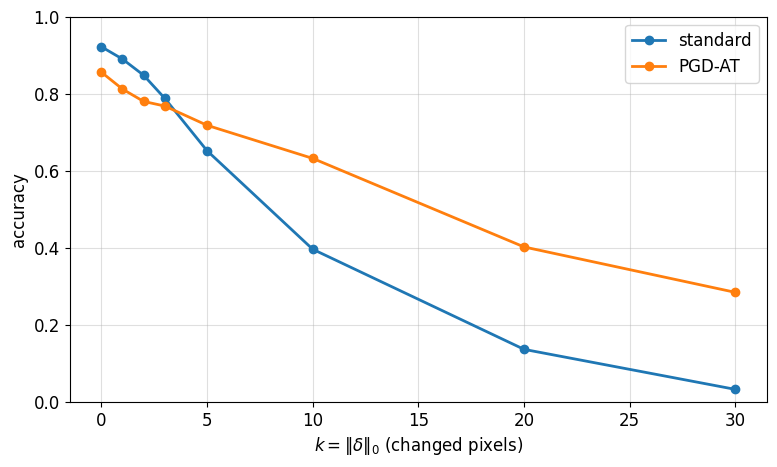

In [86]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Помогает, но только частично. При малом числе пикселей (k до 3) обычная модель даже выше, потому что у нее выше clean accuracy (0.922 против 0.856). Начиная с k = 5 PGD-AT устойчивее: при k = 10 accuracy 0.632 против 0.396, при k = 20 0.402 против 0.136, при k = 30 0.284 против 0.032. Защиты в прямом смысле при этом нет: изменения 30 пикселей из 784 (меньше 4%) хватает, чтобы уронить PGD-AT с 0.856 до 0.284, а один пиксель уже снимает 4.4 пункта. L∞-шар радиуса eps = 0.1 разрешает менять каждый пиксель не больше чем на 0.1, а L0-атака меняет пиксель с 0 до 1, то есть на величину в 10 раз больше радиуса. L∞-норма такого возмущения равна 1, оно лежит далеко за пределами шара, на котором модель обучалась, и гарантий против него нет. Частичный выигрыш, скорее всего, связан с тем, что после adversarial training модель в целом менее чувствительна к отдельным пикселям, особенно на фоне, это видно по картам в 6.3. Оценка сделана на 500 объектах, поэтому разница в пару пунктов при малых k на уровне шума.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [87]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5  clean 0.736  FGSM 0.632  PGD-20 0.052  3s
epoch 2/5  clean 0.575  FGSM 0.918  PGD-20 0.002  6s
epoch 3/5  clean 0.524  FGSM 0.940  PGD-20 0.002  9s
epoch 4/5  clean 0.483  FGSM 0.971  PGD-20 0.002  12s
epoch 5/5  clean 0.453  FGSM 0.990  PGD-20 0.001  15s
FGSM-RS
epoch 1/5  clean 0.771  FGSM 0.622  PGD-20 0.374  3s
epoch 2/5  clean 0.793  FGSM 0.651  PGD-20 0.400  6s
epoch 3/5  clean 0.792  FGSM 0.712  PGD-20 0.417  9s
epoch 4/5  clean 0.800  FGSM 0.707  PGD-20 0.427  12s
epoch 5/5  clean 0.812  FGSM 0.750  PGD-20 0.386  15s


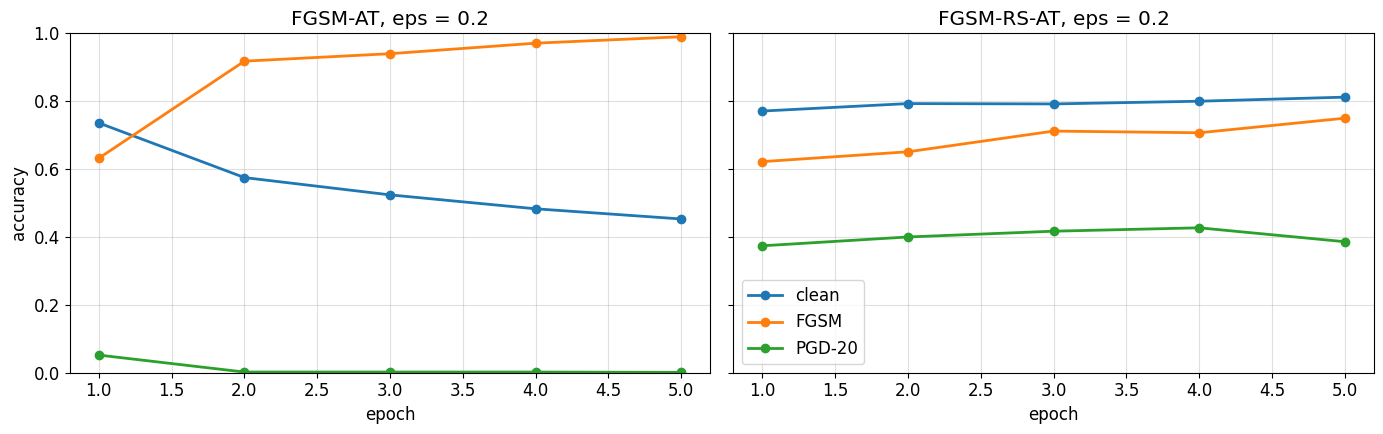

In [88]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [89]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.44140625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.7421875, 'pgd20': 0.38671875, 'pgd100_x5': 0.34375, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** Да, у FGSM-AT catastrophic overfitting есть, и случился он очень рано. После первой эпохи PGD-20 accuracy уже всего 0.052, со второй эпохи она падает до 0.002 и дальше остается около нуля. При этом FGSM accuracy растет с 0.632 до 0.990, а clean accuracy падает с 0.736 до 0.453. Если FGSM accuracy выше clean accuracy, значит, FGSM-возмущение модель только "исправляет": она научилась узнавать конкретный одношаговый паттерн, а градиент вокруг точки перестал работать для линеаризации. Усиленная проверка это подтверждает. В sanity checks, где clean ошибки считаются ошибками, у FGSM-модели fgsm 0.441, а pgd20, pgd100_x5 и eps_1 равны 0, то есть реальная robustness нулевая. Random start картину изменил. У FGSM-RS clean держится около 0.8, FGSM растет с 0.62 до 0.75, а PGD-20 остается в районе 0.37-0.43 без обвала. Sanity checks для FGSM-RS монотонные: 0.742, 0.387, 0.344 и 0 при eps = 1, признаков masking нет. Но на последней эпохе PGD немного просела (0.427 → 0.386), а Wong et al. показывают, что при большом шаге или eps FGSM-RS тоже может сорваться. Поэтому по одному seed и 5 эпохам нельзя утверждать, что random start устраняет эффект полностью.